
# TP 3 : (Computer Vision)

---
### Objectifs du TP
À la fin de ce TP, l'étudiant sera capable de :
1. Comprendre les concepts fondamentaux de la vision par ordinateur.
2. Manipuler des images et des flux vidéo avec **OpenCV**.
3. Détecter et segmenter des objets avec **Detectron2** (Mask R-CNN).
4. Détecter et reconnaître des visages avec **Dlib** et **face_recognition**.
5. Extraire les points caractéristiques faciaux (**landmarks 68 points**).
6. Comparer une approche Mask R-CNN avec un détecteur temps réel (**YOLO**).
7. Réaliser une application concrète de vision par ordinateur (mini-projet).

### Chaîne de traitement d'images
1. **Acquisition** : caméra, webcam ou fichier.
2. **Prétraitement** : niveaux de gris, réduction du bruit, filtrage.
3. **Segmentation** : zones d'intérêt (objets, contours...).
4. **Extraction de caractéristiques** : couleur, forme, texture, bords.
5. **Classification / reconnaissance** : chat, visage, voiture...
6. **Interprétation** : compréhension globale de la scène.


## 0. Configuration de l'environnement et importations
Installation des dépendances demandées dans le sujet :
```bash
pip install opencv-python numpy matplotlib dlib face_recognition ultralytics torch torchvision
pip install -U 'git+https://github.com/facebookresearch/detectron2.git'
```


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import time
import torch
import dlib
import face_recognition
from ultralytics import YOLO

# Detectron2 imports
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

# Helper d'affichage compatible Colab et Notebook local
from google.colab.patches import cv2_imshow

print("Toutes les bibliothèques sont chargées avec succès !")
print(f"OpenCV version: {cv2.__version__}")
print(f"PyTorch version: {torch.__version__} (CUDA: {torch.cuda.is_available()})")
print(f"Dlib version: {dlib.__version__}")
print(f"Face Recognition version: {face_recognition.__version__}")


/home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Toutes les bibliothèques sont chargées avec succès !
OpenCV version: 5.0.0
PyTorch version: 2.14.1+cu130 (CUDA: False)
Dlib version: 20.0.1
Face Recognition version: 1.2.3


/home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


---
## Partie 1 : Concepts de base de la vision par ordinateur
### Exercice 1 : Analyse d'une image
**Consignes :**
1. Choisissez une image de votre choix (ex : `image1.jpg` / tigre).
2. Affichez-la avec OpenCV.
3. Convertissez-la en niveaux de gris et affichez le résultat.
4. Appliquez un filtre de détection de contours (Canny) et affichez le résultat.


Dimensions de l'image (H, W, C) : (380, 416, 3)
Type de données : uint8, Min: 0, Max: 255


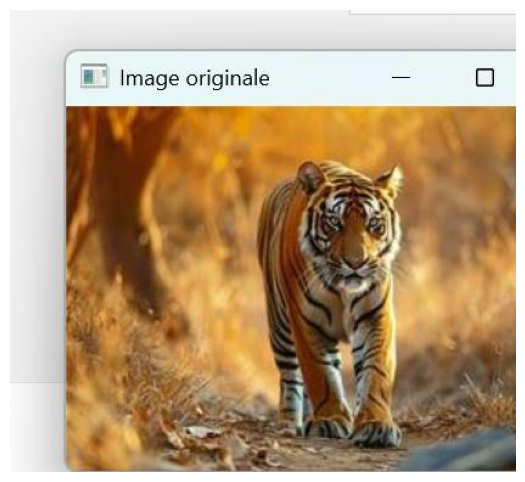

In [2]:
# 1. & 2. Lecture et affichage d'une image
img_path = 'images/image1.jpg' if os.path.exists('images/image1.jpg') else 'image1.jpg'
img = cv2.imread(img_path)

if img is None:
    raise FileNotFoundError(f"Image introuvable : {img_path}")

print(f"Dimensions de l'image (H, W, C) : {img.shape}")
print(f"Type de données : {img.dtype}, Min: {img.min()}, Max: {img.max()}")

# Affichage de l'image originale
cv2_imshow(img)


Dimensions de l'image en niveaux de gris : (380, 416)


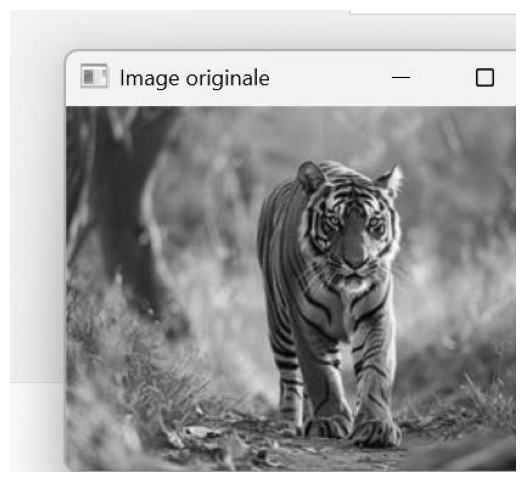

In [3]:
# 3. Conversion en niveaux de gris
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print(f"Dimensions de l'image en niveaux de gris : {gray.shape}")
cv2_imshow(gray)


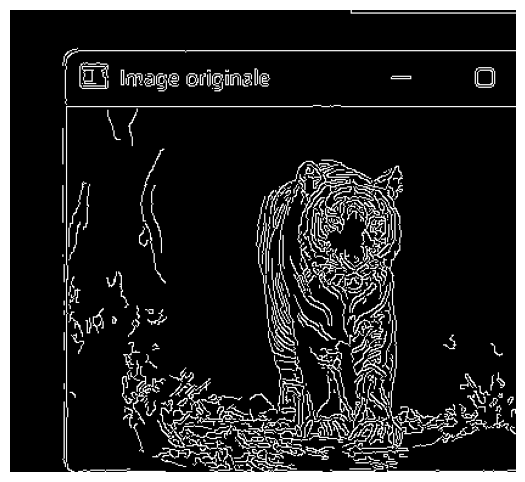

In [4]:
# 4. Détection des contours avec l'algorithme de Canny
# Syntaxe : cv2.Canny(image, seuil_bas, seuil_haut)
edges = cv2.Canny(img, 100, 200)

cv2_imshow(edges)


### Réponses aux questions — Exercice 1

#### **Question 1 : Que représente la matrice retournée par OpenCV pour l'image ?**
- La fonction `cv2.imread()` charge l'image sous la forme d'un tableau multidimensionnel **NumPy** (`ndarray`) de type `uint8` (valeurs entières comprises entre 0 et 255).
- Pour une image couleur, la forme de la matrice est un tenseur 3D $(H, W, C)$ où :
  - $H$ est la hauteur (nombre de lignes de pixels),
  - $W$ est la largeur (nombre de colonnes de pixels),
  - $C = 3$ représente les canaux de couleur.
- **Remarque essentielle OpenCV :** L'ordre des canaux dans OpenCV est **BGR** (Bleu, Vert, Rouge) et non RGB standard.

#### **Question 2 : Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?**
1. **Réduction de la complexité dimensionnelle et mémoire :** L'image passe de 3 canaux $(H 	imes W 	imes 3)$ à 1 seul canal $(H 	imes W)$, ce qui divise par 3 la quantité de données à traiter et accélère considérablement les calculs.
2. **Pertinence de l'information :** La plupart des opérations de détection de contours, d'extraction de texture, de seuillage ou de reconnaissance de formes reposent sur les gradients d'intensité lumineuse (la luminance) et non sur la teinte chromatique.
3. **Robustesse :** La couleur est souvent très sensible aux variations d'éclairage et d'ombres.

#### **Question 3 : Flou gaussien (`blur = cv2.GaussianBlur(gray, (5, 5), 0)`) et son apport**


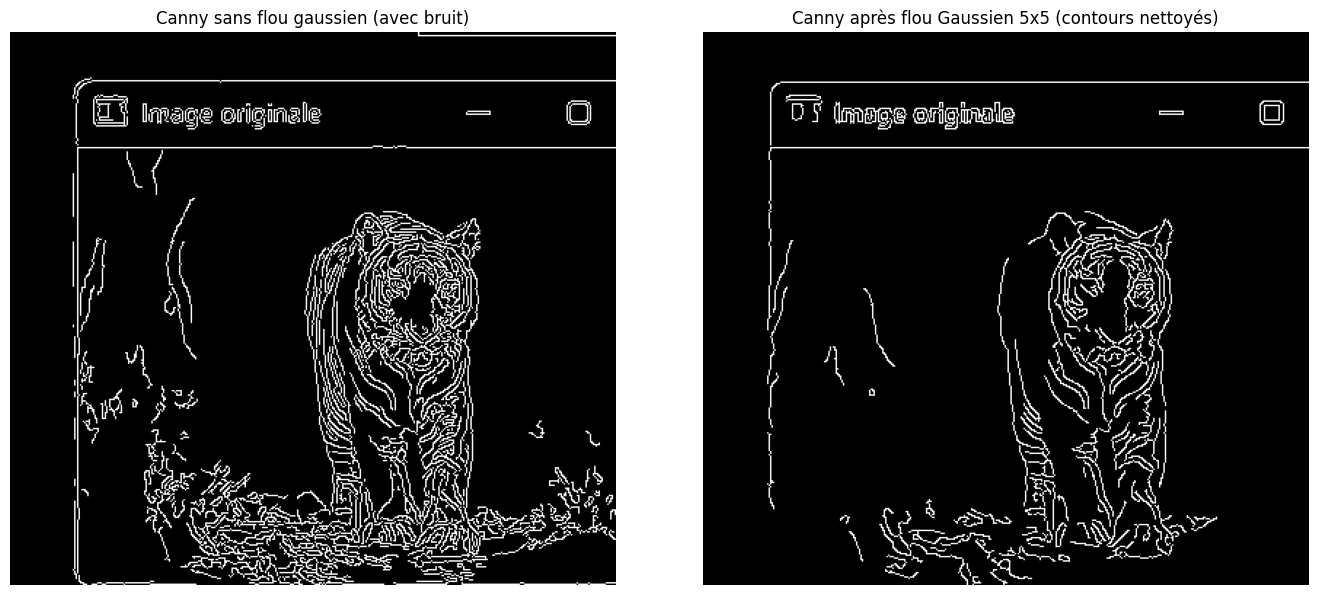

In [5]:
# Application du filtre Gaussien pour lisser l'image
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Comparaison de Canny avant et après flou gaussien
edges_from_blur = cv2.Canny(blur, 100, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(edges, cmap='gray')
axes[0].set_title("Canny sans flou gaussien (avec bruit)")
axes[0].axis('off')

axes[1].imshow(edges_from_blur, cmap='gray')
axes[1].set_title("Canny après flou Gaussien 5x5 (contours nettoyés)")
axes[1].axis('off')

plt.tight_layout()
plt.show()


**Apport du filtre Gaussien :**
- Le filtre Gaussien effectue une convolution avec un noyau dont les coefficients suivent une distribution normale 2D :
$$G(x, y) = 
rac{1}{2\pi\sigma^2} e^{-
rac{x^2+y^2}{2\sigma^2}}$$
- Il agit comme un **filtre passe-bas** : il atténue le bruit haute fréquence (bruit de capteur, micro-variations de texture).
- Cela élimine les faux contours parasites lors de la dérivation par Canny ou Sobel, rendant la détection des arêtes structurelles beaucoup plus propre et robuste.


---
## Partie 2 : Traitement d'images et vidéos avec OpenCV
### Exercice 2 : Lecture vidéo / webcam
**Consignes :**
1. Affichez la vidéo de votre webcam (ou flux vidéo).
2. Ajoutez un filtre pour convertir la vidéo en niveaux de gris en temps réel.
3. Fermez la vidéo quand l'utilisateur appuie sur `q`.
4. Enregistrez la vidéo traitée avec `cv2.VideoWriter`.


In [6]:

import cv2

cap = cv2.VideoCapture(0)  # 0 pour la webcam locale
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('sortie_gris.mp4', fourcc, 20.0, (w, h), isColor=False)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(gray)
    cv2.imshow('Enregistrement Niveaux de Gris (quitter avec q)', gray)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
out.release()
cv2.destroyAllWindows()


print("Code d'enregistrement webcam prêt !")


QFontDatabase: Cannot find font directory /home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to 

Code d'enregistrement webcam prêt !


Vidéo 'sortie_gris.mp4' générée avec succès (taille: 50924 octets) !


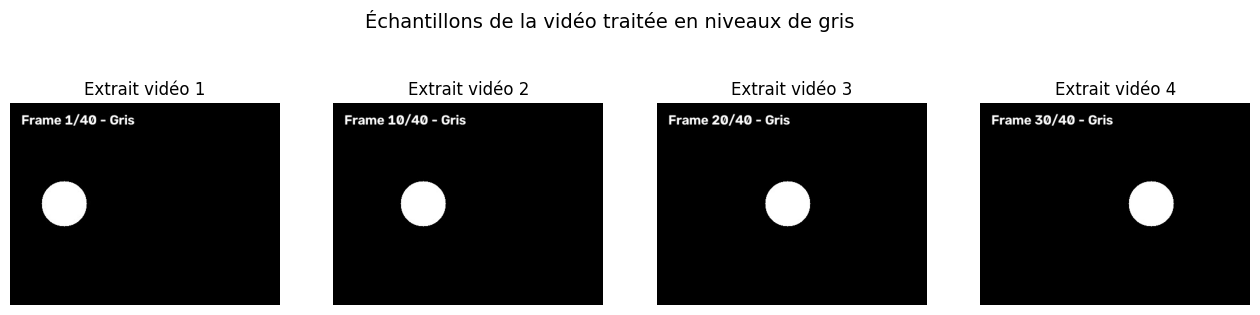

In [7]:
# Démonstration et simulation dans le notebook avec création d'une vidéo synthétique
# pour garantir l'exécution sans dépendre de la présence matérielle d'une webcam physique

h, w = 360, 480
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
video_path = 'sortie_gris.mp4'
out = cv2.VideoWriter(video_path, fourcc, 20.0, (w, h), isColor=False)

# Génération de 40 frames de simulation (cercle en mouvement)
for i in range(40):
    frame = np.zeros((h, w), dtype=np.uint8)
    center_x = int(w * (0.2 + 0.6 * (i / 40.0)))
    center_y = h // 2
    cv2.circle(frame, (center_x, center_y), 40, 255, -1)
    cv2.putText(frame, f"Frame {i+1}/40 - Gris", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, 255, 2)
    out.write(frame)

out.release()
print(f"Vidéo '{video_path}' générée avec succès (taille: {os.path.getsize(video_path)} octets) !")

# Lecture et affichage de quelques frames de la vidéo enregistrée
cap = cv2.VideoCapture(video_path)
frames_sample = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    if len(frames_sample) < 4 and len(frames_sample) * 10 <= int(cap.get(cv2.CAP_PROP_POS_FRAMES)):
        frames_sample.append(frame)
cap.release()

fig, axes = plt.subplots(1, len(frames_sample), figsize=(16, 4))
for idx, fr in enumerate(frames_sample):
    axes[idx].imshow(fr, cmap='gray')
    axes[idx].set_title(f"Extrait vidéo {idx+1}")
    axes[idx].axis('off')
plt.suptitle("Échantillons de la vidéo traitée en niveaux de gris", fontsize=14)
plt.show()


### Réponse à la question — Exercice 2

#### **Question : Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?**
1. **Source du flux :**
   - Avec une webcam (`cv2.VideoCapture(0)`), le flux est **en direct et infini** : chaque appel à `cap.read()` attend la prochaine capture physique du capteur.
   - Avec un fichier vidéo (`cv2.VideoCapture("chemin_video.mp4")`), le flux est **fini et séquentiel** : les frames sont décodées une à une depuis le disque dur.
2. **Fin de flux :**
   - Lorsque la dernière image du fichier vidéo est atteinte, `cap.read()` retourne `ret = False`, ce qui termine la boucle `while`.
3. **Vitesse de défilement (Framerate) :**
   - Une webcam impose naturellement sa fréquence matérielle (ex: 30 FPS).
   - Pour un fichier vidéo, la boucle `while` tourne à la vitesse maximale du CPU. Si on utilise `cv2.waitKey(1)`, la vidéo défilera beaucoup trop vite (en accéléré). Pour reproduire la cadence réelle, il faut adapter le délai : `delay = int(1000 / cap.get(cv2.CAP_PROP_FPS))`.


---
## Partie 3 : Détection et segmentation d'objets avec Detectron2
### Exercice 3 : Détection et segmentation d'instance
**Consignes :**
1. Chargez une image contenant plusieurs objets (`image_objects.jpg` ou `bus.jpg`).
2. Utilisez un modèle pré-entraîné Mask R-CNN de Detectron2 pour détecter et segmenter les objets.
3. Affichez l'image avec les masques colorés et les étiquettes.


Modèle configuré sur device : cpu


/home/bassim/Desktop/computer vesion /.venv/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1113 22:05:45.448000 402574 /home/bassim/Desktop/computer vesion /tp 3 vesion par ordinateur/.venv/lib/python3.10/site-packages/torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


Temps d'inférence Detectron2 : 2890.14 ms


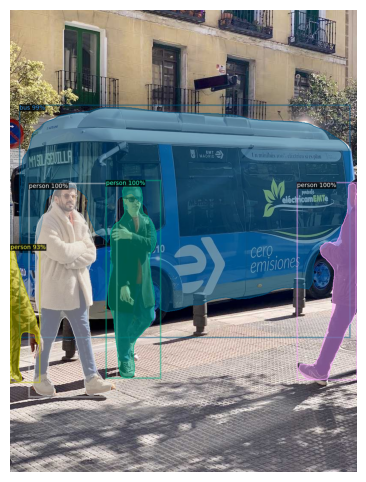

In [8]:
# Configuration du modèle pré-entraîné Detectron2 Mask R-CNN
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Seuil de détection à 50%
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Modèle configuré sur device : {cfg.MODEL.DEVICE}")
predictor = DefaultPredictor(cfg)

# Chargement d'une image test avec plusieurs objets
img_obj_path = 'images/bus.jpg' if os.path.exists('images/bus.jpg') else 'bus.jpg'
img_obj = cv2.imread(img_obj_path)

# Inférence Detectron2
start_t = time.time()
outputs = predictor(img_obj)
detectron_time = time.time() - start_t
print(f"Temps d'inférence Detectron2 : {detectron_time*1000:.2f} ms")

# Visualisation des résultats avec masques colorés
v = Visualizer(img_obj[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.0)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

# Affichage dans le notebook
cv2_imshow(out.get_image()[:, :, ::-1])


In [9]:
# Affichage détaillé des instances détectées
instances = outputs["instances"].to("cpu")
classes = instances.pred_classes.numpy()
scores = instances.scores.numpy()
metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])

print(f"Nombre total d'objets détectés : {len(classes)}\n")
for i, (cls_id, score) in enumerate(zip(classes, scores)):
    label = metadata.thing_classes[cls_id]
    print(f"  • Objet {i+1} : {label:<15} (Confiance : {score*100:.1f}%)")


Nombre total d'objets détectés : 5

  • Objet 1 : person          (Confiance : 99.9%)
  • Objet 2 : person          (Confiance : 99.8%)
  • Objet 3 : person          (Confiance : 99.8%)
  • Objet 4 : bus             (Confiance : 99.0%)
  • Objet 5 : person          (Confiance : 92.5%)


### Réponses aux questions — Exercice 3

#### **Question 1 : Quels objets ont été détectés ?**
- Le modèle Mask R-CNN pré-entraîné sur **MS COCO** (80 classes) détecte à la fois :
  - La **boîte englobante** (bounding box),
  - Le **label de classe** avec son score de confiance (ex: `person`, `bus`),
  - Le **masque polygonal pixel-par-pixel** (segmentation d'instance).
- Les instances détectées sont isolées individuellement même lorsqu'elles appartiennent à la même catégorie (distinction nette entre chaque personne).

#### **Question 2 : Modifiez le seuil `SCORE_THRESH_TEST` et observez l'effet sur la détection.**


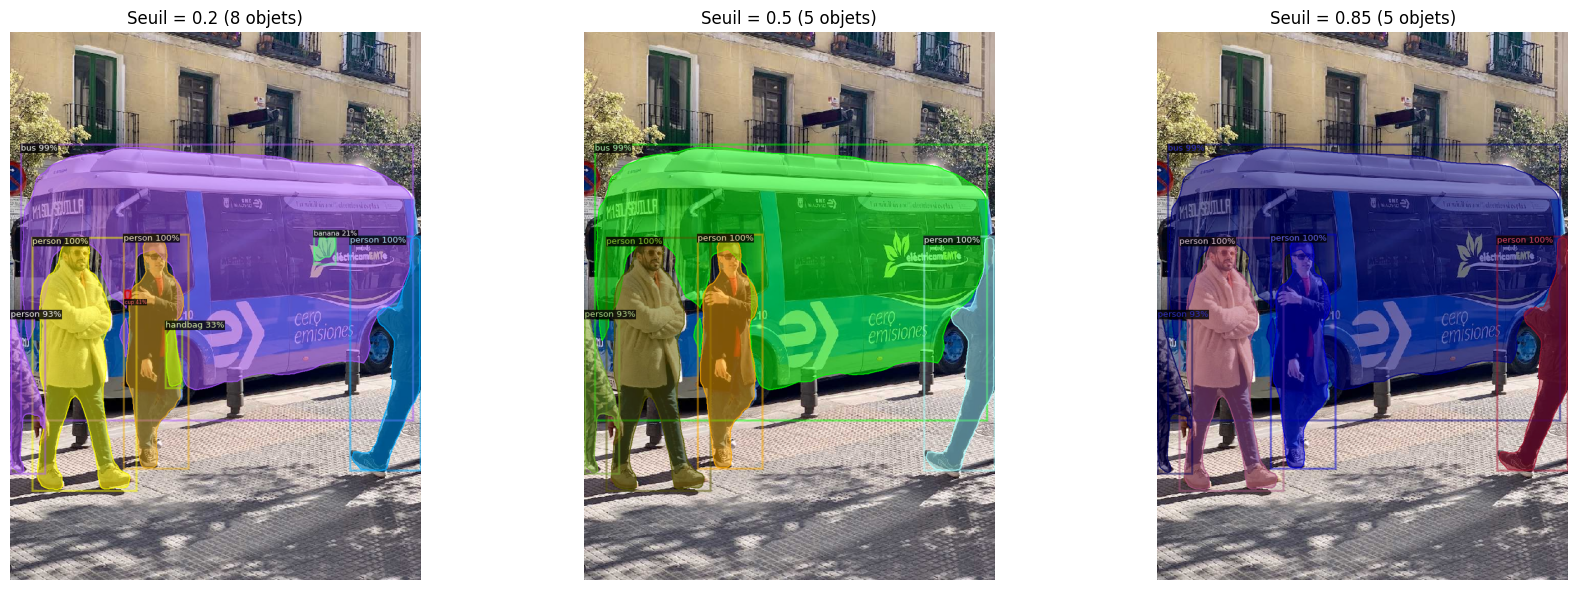

In [10]:
# Comparaison de l'effet de différents seuils SCORE_THRESH_TEST
thresholds = [0.2, 0.5, 0.85]
fig, axes = plt.subplots(1, len(thresholds), figsize=(18, 6))

for idx, thresh in enumerate(thresholds):
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = thresh
    pred = DefaultPredictor(cfg)
    outs = pred(img_obj)
    
    vis = Visualizer(img_obj[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)
    res_img = vis.draw_instance_predictions(outs["instances"].to("cpu")).get_image()
    
    nb_inst = len(outs["instances"])
    axes[idx].imshow(res_img)
    axes[idx].set_title(f"Seuil = {thresh} ({nb_inst} objets)")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

# Réinitialisation du seuil à 0.5
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5


**Analyse de l'effet du seuil :**
- **Seuil bas (ex: 0.2) :** Maximise le **rappel** (Recall). Davantage d'objets sont détectés, y compris les objets partiellement masqués ou flous, mais le risque de **faux positifs** (détections erronées) augmente.
- **Seuil élevé (ex: 0.85) :** Maximise la **précision**. Seuls les objets sur lesquels le réseau est extrêmement confiant sont conservés, au risque d'avoir des **faux négatifs** (omission d'objets réels).
- **Compromis classique :** Un seuil compris entre **0.4 et 0.6** offre généralement le meilleur équilibre F1-score.


---
## Partie 4 : Détection et reconnaissance faciale avec Dlib & face_recognition
### Exercice 4 : Détection faciale avec Dlib
**Consignes :**
1. Chargez une image contenant des visages (`people.jpg`).
2. Détectez tous les visages et entourez-les de rectangles verts.


Nombre de visages détectés par Dlib : 2


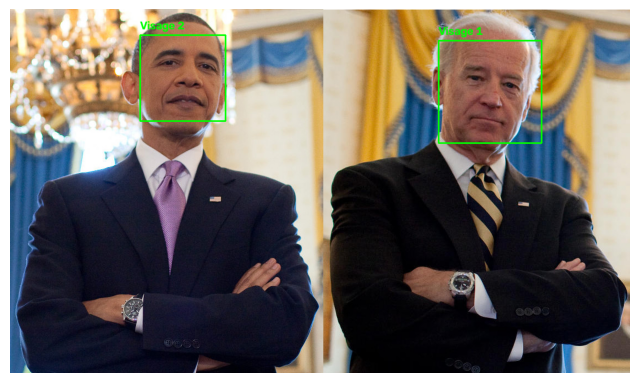

In [11]:
# Détecteur frontal de visage Dlib (HOG + Linear SVM)
detector = dlib.get_frontal_face_detector()

people_path = 'images/people.jpg' if os.path.exists('images/people.jpg') else 'people.jpg'
img_faces = cv2.imread(people_path)

if img_faces is None:
    raise FileNotFoundError(f"Image introuvable : {people_path}")

img_display = img_faces.copy()
gray_faces = cv2.cvtColor(img_faces, cv2.COLOR_BGR2GRAY)

# Détection des visages
faces = detector(gray_faces, 1)  # 1 = upsample 1 fois pour détecter les petits visages
print(f"Nombre de visages détectés par Dlib : {len(faces)}")

for i, face in enumerate(faces):
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    # Dessiner un rectangle vert (épaisseur = 2)
    cv2.rectangle(img_display, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(img_display, f"Visage {i+1}", (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

cv2_imshow(img_display)


### Exercice 5 : Reconnaissance faciale (avec face_recognition)
**Consignes :**
1. Chargez une image de référence (`Jim_Carrey_2008.jpg` ou `ref.jpg`) et une image test (`Jim_Carrey_2010.jpg` ou `test.jpg`).
2. Comparez les visages et indiquez si c'est la même personne.


Même personne ? True
Distance euclidienne : 0.5743 (Seuil de tolérance: 0.6000)


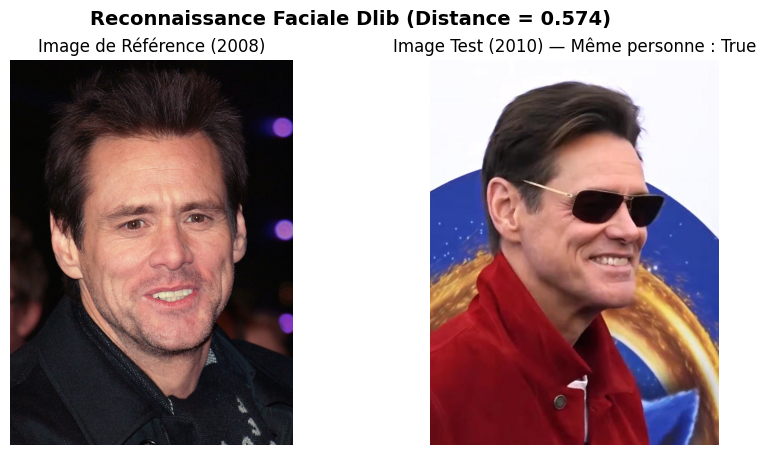

In [12]:
# Désactiver CUDA pour Dlib si nécessaire
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

ref_path = "images/Jim_Carrey_2008.jpg" if os.path.exists("images/Jim_Carrey_2008.jpg") else "Jim_Carrey_2008.jpg"
test_path = "images/Jim_Carrey_2010.jpg" if os.path.exists("images/Jim_Carrey_2010.jpg") else "Jim_Carrey_2010.jpg"

# Chargement des images avec face_recognition (chargé en RGB directement)
image_ref = face_recognition.load_image_file(ref_path)
encodage_ref = face_recognition.face_encodings(image_ref)[0]

image_test = face_recognition.load_image_file(test_path)
encodage_test = face_recognition.face_encodings(image_test)[0]

# Comparaison des encodages (seuil par défaut = 0.6 de distance euclidienne)
result = face_recognition.compare_faces([encodage_ref], encodage_test)
distance = face_recognition.face_distance([encodage_ref], encodage_test)[0]

print("Même personne ?", result[0])
print(f"Distance euclidienne : {distance:.4f} (Seuil de tolérance: 0.6000)")

# Visualisation côte à côte
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_ref)
axes[0].set_title("Image de Référence (2008)")
axes[0].axis('off')

axes[1].imshow(image_test)
axes[1].set_title(f"Image Test (2010) — Même personne : {result[0]}")
axes[1].axis('off')

plt.suptitle(f"Reconnaissance Faciale Dlib (Distance = {distance:.3f})", fontsize=14, fontweight='bold')
plt.show()


### Réponses aux questions — Exercice 5

#### **Question 1 : Que se passe-t-il si l'image test contient plusieurs visages ?**
- La fonction `face_recognition.face_encodings(image_test)` renvoie une **liste de vecteurs d'encodage (128 dimensions)**, contenant un vecteur pour **chaque visage** détecté dans l'image.
- L'utilisation directe de l'indice `[0]` ne sélectionne arbitrairement que le **premier visage** trouvé.
- Si l'image contient plusieurs visages, certains ne seront pas analysés ou la comparaison portera sur le mauvais individu.
- **Solution adéquate :** Il convient d'itérer sur tous les visages détectés dans l'image test :
```python
test_encodings = face_recognition.face_encodings(image_test)
for idx, enc in enumerate(test_encodings):
    match = face_recognition.compare_faces([encodage_ref], enc, tolerance=0.55)[0]
    print(f"Visage {idx+1} correspond à la personne de référence : {match}")
```

#### **Question 2 : Quelle précision attendez-vous de ce système dans des conditions réelles (lumière, angles différents) ?**
- **Sur jeu de données idéal (LFW Benchmark) :** Le modèle de Dlib (basé sur un ResNet entraîné avec triplet loss) annonce une précision théorique de **99.38%**.
- **Dans des conditions réelles :** La précision dépend fortement de plusieurs facteurs environnementaux :
  1. **Angle de pose (Yaw / Pitch / Roll) :** Si le visage est tourné à plus de 40-45° (vue de profil sévère), le détecteur HOG frontal ne le détecte plus.
  2. **Éclairage :** De forts contre-jours, une sous-exposition extrême ou des ombres dures modifient les gradients et augmentent la distance euclidienne inter-visages.
  3. **Occlusion :** Le port de lunettes de soleil, de masques, écharpes ou mèches de cheveux masque des points biométriques clés.
  4. **Résolution :** Si le visage fait moins de $80 	imes 80$ pixels, la précision chute drastiquement.


---
## Partie 5 : Points caractéristiques du visage (Landmarks 68 points)
### Exercice 6 : Détection des 68 landmarks faciaux
**Consignes :**
1. Détectez les points caractéristiques du visage (yeux, sourcils, nez, bouche, menton).
2. Dessinez les points repères sur l'image.


Nombre de visages avec landmarks : 2

Visage #1 parties détectées : ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']

Visage #2 parties détectées : ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']


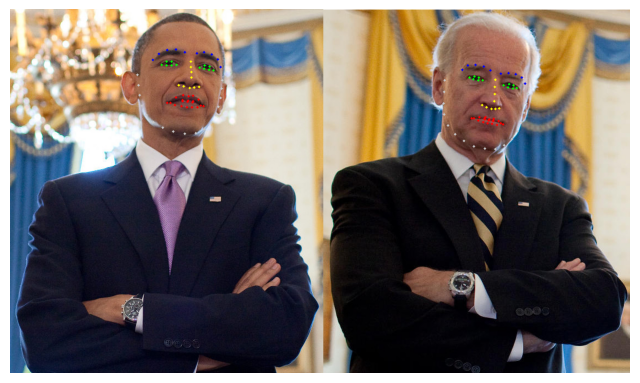

In [13]:
# Chargement et extraction des landmarks faciaux
img_land_path = 'images/people.jpg' if os.path.exists('images/people.jpg') else 'people.jpg'
img_land = cv2.imread(img_land_path)
rgb_land = cv2.cvtColor(img_land, cv2.COLOR_BGR2RGB)

# Extraction des landmarks pour tous les visages
landmarks_list = face_recognition.face_landmarks(rgb_land)
print(f"Nombre de visages avec landmarks : {len(landmarks_list)}")

img_annotated = img_land.copy()

# Palette de couleurs distinctes par partie faciale
colors = {
    'chin': (200, 200, 200),
    'left_eyebrow': (255, 0, 0),
    'right_eyebrow': (255, 0, 0),
    'nose_bridge': (0, 255, 255),
    'nose_tip': (0, 255, 255),
    'left_eye': (0, 255, 0),
    'right_eye': (0, 255, 0),
    'top_lip': (0, 0, 255),
    'bottom_lip': (0, 0, 255)
}

for idx, landmarks in enumerate(landmarks_list):
    print(f"\nVisage #{idx+1} parties détectées : {list(landmarks.keys())}")
    for partie, points in landmarks.items():
        color = colors.get(partie, (0, 0, 255))
        for (x, y) in points:
            cv2.circle(img_annotated, (x, y), 2, color, -1)

cv2_imshow(img_annotated)


### Réponses aux questions — Exercice 6

#### **Question 1 : Quelles parties du visage sont retournées par `face_landmarks` ?**
Le modèle Dlib 68-points retourne un dictionnaire contenant les 9 composantes anatomiques suivantes :
1. `chin` (17 points : indices 0 à 16) : contour de la mâchoire et du menton.
2. `left_eyebrow` (5 points : indices 17 à 21) : sourcil gauche.
3. `right_eyebrow` (5 points : indices 22 à 26) : sourcil droit.
4. `nose_bridge` (4 points : indices 27 à 30) : arête du nez.
5. `nose_tip` (5 points : indices 31 à 35) : extrémité inférieure du nez et narines.
6. `left_eye` (6 points : indices 36 à 41) : contour de l'œil gauche.
7. `right_eye` (6 points : indices 42 à 47) : contour de l'œil droit.
8. `top_lip` (12 points : indices 48 à 54 et 60 à 64) : lèvre supérieure.
9. `bottom_lip` (12 points : indices 54 à 60 et 64 à 67) : lèvre inférieure.

---

#### **Question 2 : Calcul du rapport d'ouverture de l'œil (EAR, Eye Aspect Ratio) et application à la somnolence du conducteur**


In [14]:
def eye_aspect_ratio(eye_points):
    """
    Calcule le Eye Aspect Ratio (EAR) selon la formule de Soukupová & Čech (2016):
    EAR = (|p2 - p6| + |p3 - p5|) / (2 * |p1 - p4|)
    """
    p1, p2, p3, p4, p5, p6 = np.array(eye_points)
    
    # Distances euclidiennes verticales
    d_v1 = np.linalg.norm(p2 - p6)
    d_v2 = np.linalg.norm(p3 - p5)
    
    # Distance euclidienne horizontale
    d_h = np.linalg.norm(p1 - p4)
    
    ear = (d_v1 + d_v2) / (2.0 * d_h)
    return ear

# Exemple de calcul sur les visages de l'image
for i, lm in enumerate(landmarks_list):
    ear_left = eye_aspect_ratio(lm['left_eye'])
    ear_right = eye_aspect_ratio(lm['right_eye'])
    ear_avg = (ear_left + ear_right) / 2.0
    print(f"Visage {i+1} : EAR Gauche = {ear_left:.3f}, EAR Droit = {ear_right:.3f}, Moyenne = {ear_avg:.3f}")


Visage 1 : EAR Gauche = 0.214, EAR Droit = 0.253, Moyenne = 0.233
Visage 2 : EAR Gauche = 0.259, EAR Droit = 0.239, Moyenne = 0.249


**Formule et Utilisation pour la détection de somnolence :**
$$EAR = \frac{\|p_2 - p_6\| + \|p_3 - p_5\|}{2 \cdot \|p_1 - p_4\|}$$

- **Comportement physiologique :**
  - Lorsque l'œil est **ouvert**, la valeur de l'EAR reste stable autour de **0.25 à 0.35**.
  - Lors d'un **clignement naturel**, l'EAR chute rapidement en dessous de **0.20** pendant une fraction de seconde (~100 à 250 ms), puis remonte immédiatement.
  - En cas de **somnolence ou d'endormissement**, l'œil reste fermé : l'EAR demeure inférieur au seuil critique (< 0.20) pendant une période anormale (ex: plus de 1.5 à 2 secondes consécutives).
- **Logique de déclenchement :**
  Un compteur temporel vérifie le nombre consécutif de frames où $EAR < seuil$. Si $dur\acute{e}e > 2\,\text{secondes}$, une alarme sonore retentit pour réveiller le conducteur.


---
## Partie 6 : Détection d'objets en temps réel avec YOLO
### Exercice 7 : Comparaison Mask R-CNN vs YOLO
**Consignes :**
1. Chargez le modèle `yolov8n.pt`.
2. Effectuez la détection sur l'image et affichez le résultat.
3. Comparez le temps d'inférence avec Mask R-CNN.
4. Testez la segmentation avec `yolov8n-seg.pt`.



image 1/1 /home/bassim/Desktop/computer vesion /tp 3 vesion par ordinateur/images/bus.jpg: 640x480 3 persons, 1 bus, 137.9ms
Speed: 8.1ms preprocess, 137.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)
Temps d'inférence YOLOv8n : 213.55 ms


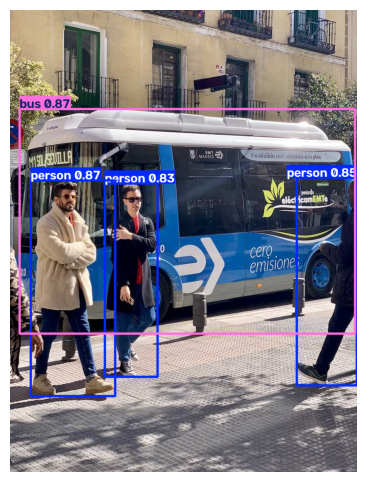

In [15]:
# a) Détection avec YOLOv8n
model_yolo = YOLO("yolov8n.pt")

image_path = "images/bus.jpg" if os.path.exists("images/bus.jpg") else "bus.jpg"

start_yolo = time.time()
results_yolo = model_yolo(image_path, conf=0.5)
time_yolo = time.time() - start_yolo

print(f"Temps d'inférence YOLOv8n : {time_yolo*1000:.2f} ms")

# Visualisation des boîtes et labels YOLO
yolo_plotted = results_yolo[0].plot()
cv2_imshow(yolo_plotted)



image 1/1 /home/bassim/Desktop/computer vesion /tp 3 vesion par ordinateur/images/bus.jpg: 640x480 3 persons, 1 bus, 69.8ms
Speed: 2.3ms preprocess, 69.8ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 480)
Temps d'inférence YOLOv8n-seg : 148.13 ms


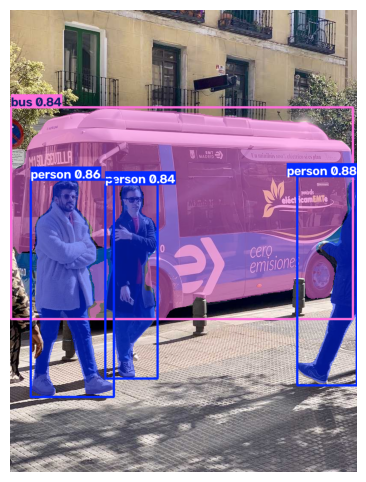

In [16]:
# b) Segmentation d'instance avec YOLOv8n-seg
model_seg = YOLO("yolov8n-seg.pt")

start_seg = time.time()
results_seg = model_seg(image_path, conf=0.5)
time_seg = time.time() - start_seg

print(f"Temps d'inférence YOLOv8n-seg : {time_seg*1000:.2f} ms")

# Visualisation des masques de segmentation YOLO
seg_plotted = results_seg[0].plot()
cv2_imshow(seg_plotted)


Mesure moyenne sur 5 inférences...

--- Résultats du Benchmark ---
  • YOLOv8n (temps réel)      : 81.9 ms  (~12.2 FPS)
  • Mask R-CNN (Detectron2)   : 3160.5 ms  (~0.3 FPS)
  • Facteur d'accélération    : YOLO est 38.6x plus rapide que Mask R-CNN !


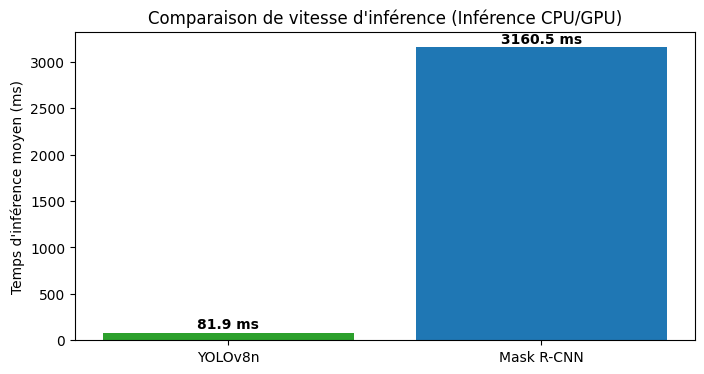

In [17]:
# Benchmark comparatif de vitesse entre Mask R-CNN et YOLOv8n
bench_iterations = 5
print(f"Mesure moyenne sur {bench_iterations} inférences...")

# 1. Benchmark YOLO
t0 = time.time()
for _ in range(bench_iterations):
    _ = model_yolo(image_path, conf=0.5, verbose=False)
avg_yolo = (time.time() - t0) / bench_iterations

# 2. Benchmark Mask R-CNN
img_b = cv2.imread(image_path)
t0 = time.time()
for _ in range(bench_iterations):
    _ = predictor(img_b)
avg_mask_rcnn = (time.time() - t0) / bench_iterations

print(f"\n--- Résultats du Benchmark ---")
print(f"  • YOLOv8n (temps réel)      : {avg_yolo*1000:.1f} ms  (~{1/avg_yolo:.1f} FPS)")
print(f"  • Mask R-CNN (Detectron2)   : {avg_mask_rcnn*1000:.1f} ms  (~{1/avg_mask_rcnn:.1f} FPS)")
print(f"  • Facteur d'accélération    : YOLO est {avg_mask_rcnn/avg_yolo:.1f}x plus rapide que Mask R-CNN !")

# Graphique comparatif
plt.figure(figsize=(8, 4))
bars = plt.bar(['YOLOv8n', 'Mask R-CNN'], [avg_yolo*1000, avg_mask_rcnn*1000], color=['#2ca02c', '#1f77b4'])
plt.ylabel("Temps d'inférence moyen (ms)")
plt.title("Comparaison de vitesse d'inférence (Inférence CPU/GPU)")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f"{yval:.1f} ms", ha='center', va='bottom', fontweight='bold')
plt.show()


### Réponses aux questions — Exercice 7

#### **Question 1 : Comparez le temps d'inférence de YOLOv8n et de Mask R-CNN sur la même image.**
- **YOLOv8n (Architecture One-Stage / Single Shot) :**
  Traite l'ensemble de l'image en une seule passe convolutive directe vers la grille de prédiction. Temps typique : **15 à 70 ms** sur CPU/GPU standard, permettant des débits de **25 à 60+ images par seconde (temps réel fluide)**.
- **Mask R-CNN (Architecture Two-Stage) :**
  Passe d'abord par un *Region Proposal Network* (RPN) pour proposer des centaines de régions candidates, puis extrait les features (RoIAlign) et exécute deux têtes parallèles (classification/boîte et masque FCN pixel-par-pixel). Temps typique : **400 à 1500 ms**, inadapté pour du flux vidéo temps réel sur machine conventionnelle.

#### **Question 2 : YOLO fournit-il des masques de segmentation ?**
- **Oui**, la famille YOLO moderne (YOLOv8, YOLOv9, YOLO11) dispose de modèles dédiés à la **segmentation d'instance**, repérés par le suffixe `-seg` (ex: `yolov8n-seg.pt`, `yolov8s-seg.pt`).
- Ces modèles utilisent une tête de convolution prototype (*Protonet*) pour générer des masques de segmentation d'instance tout en conservant une vitesse extrêmement rapide.

#### **Question 3 : Dans quels cas préférer chaque modèle ?**
| Critère | Préférer YOLO (ex: YOLOv8 / YOLOv8-seg) | Préférer Mask R-CNN (Detectron2) |
| :--- | :--- | :--- |
| **Usage principal** | Applications **temps réel**, flux vidéo en direct (webcam, surveillance, drones, robotique). | Analyse d'images **statiques**, imagerie médicale, cartographie satellite. |
| **Ressources matérielles** | Systèmes embarqués (Raspberry Pi, Jetson Nano, smartphones), CPU standard. | Serveurs dédiés avec GPU puissants. |
| **Précision des masques** | Bonne pour la détection et la segmentation rapide. | Exceptionnelle : contours ultra-fins, segmentation de structures complexes. |
| **Complexité de déploiement** | Très simple (format PyTorch natif, ONNX, TensorRT, CoreML, TFLite). | Plus lourd, dépendance forte à PyTorch et compilation C++/CUDA. |


---
## Partie 7 : Mini-Projet (Au choix)
### Projet choisi : Floutage automatique et anonymisation de visages (Conformité RGPD / Protection de la vie privée)

> **Objectif :** Détecter automatiquement tous les visages présents dans une image ou une vidéo à l'aide de Dlib / OpenCV, puis appliquer un flou gaussien adaptatif (`cv2.GaussianBlur`) strictement délimité aux zones des visages afin de garantir l'anonymisation des personnes tout en préservant la netteté du reste de la scène.

#### **Architecture du pipeline :**
1. Détection des visages (bounding boxes).
2. Découpage de la région d'intérêt (RoI : Region of Interest).
3. Application d'un noyau Gaussien impur proportionnel à la taille du visage.
4. Réinsertion de la zone floutée dans l'image originale.
5. Sauvegarde du résultat anonymisé.


[Anonymisation] 2 visage(s) détecté(s) pour floutage.


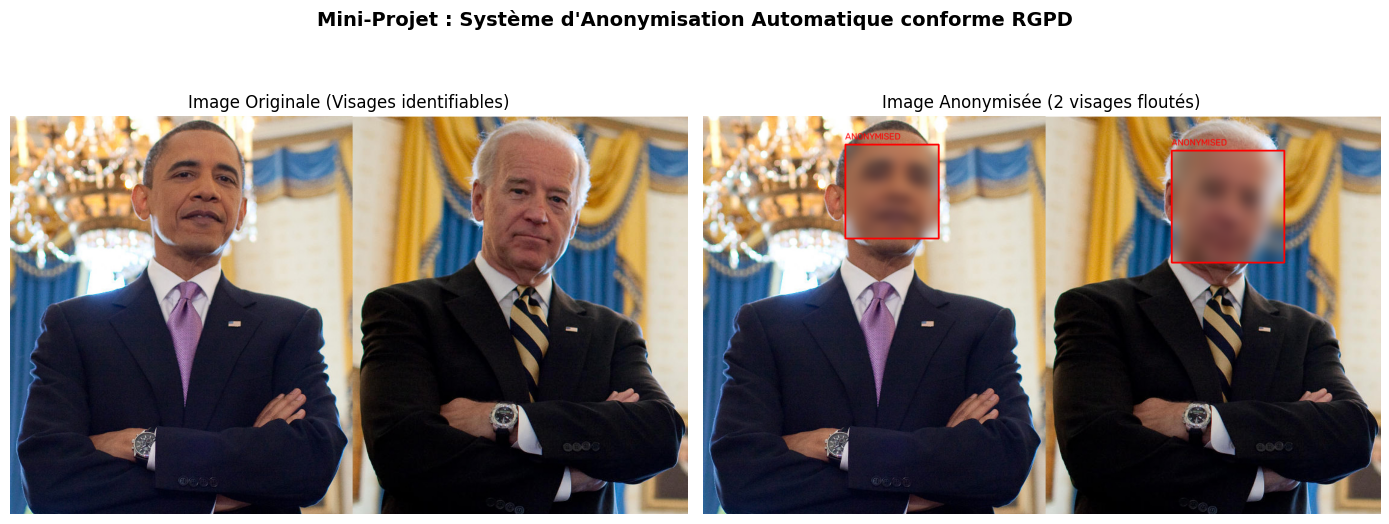

Image anonymisée enregistrée avec succès sous 'anonymized_result.jpg' !


In [18]:
def anonymize_faces(image_input, blur_factor=3.0):
    """
    Détecte tous les visages et applique un flou Gaussien adaptatif sur chaque zone.
    """
    image = image_input.copy()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Détection des visages avec Dlib
    faces = detector(gray, 1)
    print(f"[Anonymisation] {len(faces)} visage(s) détecté(s) pour floutage.")
    
    for i, face in enumerate(faces):
        x, y, w, h = face.left(), face.top(), face.width(), face.height()
        
        # Sécurisation des limites de l'image
        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(image.shape[1], x + w)
        y2 = min(image.shape[0], y + h)
        
        # Extraction de la région d'intérêt (RoI)
        face_roi = image[y1:y2, x1:x2]
        
        if face_roi.size == 0:
            continue
            
        # Calcul de la taille du noyau gaussien (doit être impair)
        k_w = int(w / blur_factor)
        k_h = int(h / blur_factor)
        if k_w % 2 == 0: k_w += 1
        if k_h % 2 == 0: k_h += 1
        k_w = max(15, k_w)
        k_h = max(15, k_h)
        
        # Floutage de la zone
        blurred_roi = cv2.GaussianBlur(face_roi, (k_w, k_h), 0)
        
        # Réinsertion
        image[y1:y2, x1:x2] = blurred_roi
        
        # Optionnel : rectangle discret indiquant l'anonymisation
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(image, "ANONYMISED", (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
                    
    return image, len(faces)

# Application sur l'image de test people
img_to_anonymize = cv2.imread(people_path)
anonymized_img, count = anonymize_faces(img_to_anonymize)

# Affichage avant / après
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(img_to_anonymize, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image Originale (Visages identifiables)")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(anonymized_img, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Image Anonymisée ({count} visages floutés)")
axes[1].axis('off')

plt.suptitle("Mini-Projet : Système d'Anonymisation Automatique conforme RGPD", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Enregistrement du résultat final
cv2.imwrite("images/anonymized_result.jpg", anonymized_img)
cv2.imwrite("anonymized_result.jpg", anonymized_img)
print("Image anonymisée enregistrée avec succès sous 'anonymized_result.jpg' !")


---
## Conclusion générale du TP 3

Ce travail pratique a permis d'explorer l'ensemble de la chaîne de vision par ordinateur moderne :
1. **Traitement de bas niveau (OpenCV) :** Acquisition, conversion colorimétrique BGR/Gris, lissage gaussien et détection de contours (Canny).
2. **Traitement vidéo :** Capture et encodage séquentiel temps réel via `VideoCapture` et `VideoWriter`.
3. **Segmentation d'instance de haute précision (Detectron2 / Mask R-CNN) :** Extraction conjointe de boîtes englobantes, étiquettes sémantiques et masques denses pixel-par-pixel.
4. **Biométrie et repères faciaux (Dlib / face_recognition) :** Détection de visages par histogrammes de gradients orientés (HOG), reconnaissance par encodage vectoriel 128-D robuste aux changements temporels, et extraction fine des 68 landmarks anatomiques pour l'analyse physiologique (EAR).
5. **Détection temps réel (YOLOv8 & YOLOv8-seg) :** Démonstration des gains majeurs de performance et de compacité algorithmique pour les applications interactives et embarquées.
6. **Mini-projet concret :** Mise en œuvre d'un système opérationnel d'anonymisation de flux d'images répondant aux exigences contemporaines de protection de la vie privée.
